### 2026년 11월 23일 (월) TIL
> re_ml 파일명 뜻: 다시하는(retry) 머신러닝

### 오늘의 수업 주제
- 1부: AI 리터러시
- 2부: 머신러닝에 필요한 작업 (해당 문서는 2부만 서술)

오늘 실습한 내용 정리
- 

In [ ]:

# 타이타닉 승객 표를 불러와 크기, 자료형, 빈칸 개수, 숫자 요약을 읽어보자 

# 데이터 불러오기 
import pandas as pd 
import numpy as np
import seaborn as sns

df = sns.load_dataset('titanic')
# df.head(5)
# df.shape
# df.info()
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# 글자로 착각한 숫자 고치기 
# ₩기호와 쉼표가 붙은 가격이 괘 계산되지 않는지 확인하고 숫자로 바꿔 평균을 구함 

shop = pd.DataFrame({
    "상품":["텀블러", "에코백", "무선 이어폰", "충전기", "노트", "보조배터리"],
    "가격":["₩12,000", "₩8,500", "₩129,000", "₩19,900", "₩3,000", "₩35,000"],
})
shop.dtypes

step1 = shop["가격"].str.replace("₩", "").str.replace(",", "")
print(step1.tolist())
print(step1.dtype)

shop["가격"] = shop["가격"].str.replace("₩", "").str.replace(",", "")
shop["가격"] = pd.to_numeric(shop["가격"])
print(shop.dtypes)
print("평균 가격:", round(shop["가격"].mean()))

['12000', '8500', '129000', '19900', '3000', '35000']
str
상품      str
가격    int64
dtype: object
평균 가격: 34567


In [ ]:
# 빈칸 채우기 (나이, 항구, 갑판)
# 칸의 성격(숫자/범주/대부분 빈칸)에 따라 다른 방법으로 빈칸을 채우고 그 선택이 분표를 바꾼다는 것을 확인

df.isnull().sum()

empty_age = df["age"].isnull()
print("나이 빈칸:", empty_age.sum(), "명")
df.loc[empty_age, ["sex", "age", "class"]].head()

print("평균:", round(df["age"].mean(), 2), "| 중앙값:", df["age"].median())

mean_age = df["age"].mean()
df.loc[:, "age"] = df["age"].fillna(mean_age)
print("남은 빈칸:", df["age"].isnull().sum())
df.loc[empty_age, ["sex", "age", "class"]].head()

나이 빈칸: 177 명
평균: 29.7 | 중앙값: 28.0
남은 빈칸: 0


,sex,age,class
5,male,29.699118,Third
17,male,29.699118,Second
19,female,29.699118,Third
26,male,29.699118,Third
28,female,29.699118,Third


In [ ]:
# 항구: 최빈값
# 탑승 항구는 글자라 평균이 없다. 가장 많이  탄 항구로 채워야한다 

df["embark_town"].value_counts(dropna=False)

mode_town = df["embark_town"].mode()[0]
print("최빈값:", mode_town)
# df.loc[:, "embark_town"] = df["embark_town"].fillna(mode_town)
# df["embark_town"].value_counts(dropna=False)

df.loc[:, "embarked"] = df["embark_town"].str[0]
# df[["embarked", "embark_town"]].insull().sum()

test = df["deck"].ffill().bfill()
pd.DataFrame({"원본": df["deck"].value_counts(), "ffill•bfill 후": test.value_counts()})

print(df["deck"].dtype)
df["deck"].cat.categories

df["deck"] = df["deck"].cat.add_categories("Unknown").fillna("Unknown")
print(df["deck"].cat.categories.tolist())
print(df["deck"].value_counts())
df.isnull().sum().sum()

최빈값: Southampton
category
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'Unknown']
deck
Unknown    688
C           59
B           47
D           33
E           32
A           15
F           13
G            4
Name: count, dtype: int64


np.int64(4)

In [ ]:
# 튀는 값(이상치) 찾기 
# IQR규칙으로 이상치 후보를 세어보고 '후보'와 '지울 값'을 구별한 뒤 명백한 값만 거른다 

# print(df["fare"].quantile([0.25, 0.5, 0.75]))
# df["fare"].describe()[["25%", "50%", "75%"]]

# q1 = df["fare"].quantile(0.25)
# q3 = df["fare"].quantile(0.75)
# iqr = q3 - q1
# upper = q3 + 1.5 * iqr
# print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, 위쪽 한계={upper:.2f}")
# print("이상치 후보:", (df["fare"] > upper).sum(), "명")
# df.loc[df["fare"] > upper, "class"].value_counts()

# before = len(df)
# df = df[df["fare"] < 300].copy()
# print(before, "->", len(df), "명")

print("중복 행:", df.duplicated().sum(), "개")
df[df.duplicated(keep=False)].sort_values(["fare", "age"]).head(6)

중복 행: 107 개


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
277,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,Southampton,no,True
413,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,Southampton,no,True
466,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,Southampton,no,True
481,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,Southampton,no,True
674,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,Southampton,no,True
732,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,Southampton,no,True


In [ ]:
# 값을 바꿨는데 안 바뀐다 (copy-on-write)
# 대괄호를 두 번 이어 쓰는 할당이 원본을 바꾸지 못하는 이유를 보고 .loc한번으로 고친다 

t = df.copy()
t["age"][0]=99
t.loc[0, "age"]

t.loc[0, "age"] = 99
t.loc[0, "age"]

first = t[t["class"] == "First"]
first.loc[:, "fare"] = 0
print("first 평균:", first["fare"].mean())
print("원본 1등식 평균", round(t.loc[t["class"] == "First", "fare"].mean(), 2))

first 평균: 0.0
원본 1등식 평균 84.15


C:\Users\USER\AppData\Local\Temp\ipykernel_9368\1659777129.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  t["age"][0]=99


In [ ]:
# 한글 폰트 준비 
# 운영체제에 맞게 한글 폰트를 설정하는 셀을 만드세요 


import platform
import matplotlib.pyplot as plt

os_name = platform.system()
if os_name == "windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif os_name == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
else:
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False


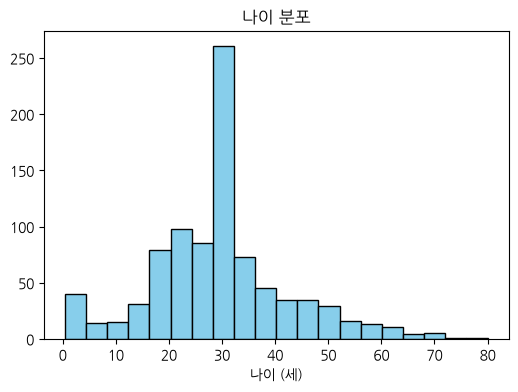

In [ ]:
# 그래프 세 장 
# 나이 히스토그램, 등급별 요금 박스 플롯, 나이-요금 산점도(생존 여부 색)를 나란히 그리세요 

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df["age"], bins=20, color="skyblue", edgecolor="black")
ax.set_title("나이 분포")
ax.set_xlabel("나이 (세)")
plt.show()

#### 위 그래프 따라치다가 생긴 문제: 한글 폰트 깨짐 현상

해결과정 
1. 내가 코드를 잘못쓴건 없는지 확인 
2. 주피터노트 리스타트, run all 해보기 
3. 에러내용 구글링 해보기 
4. 맑은 고딕 폰트 새로 다운로드 받기 
5. vs code 껐다 켜기 
6. 해결

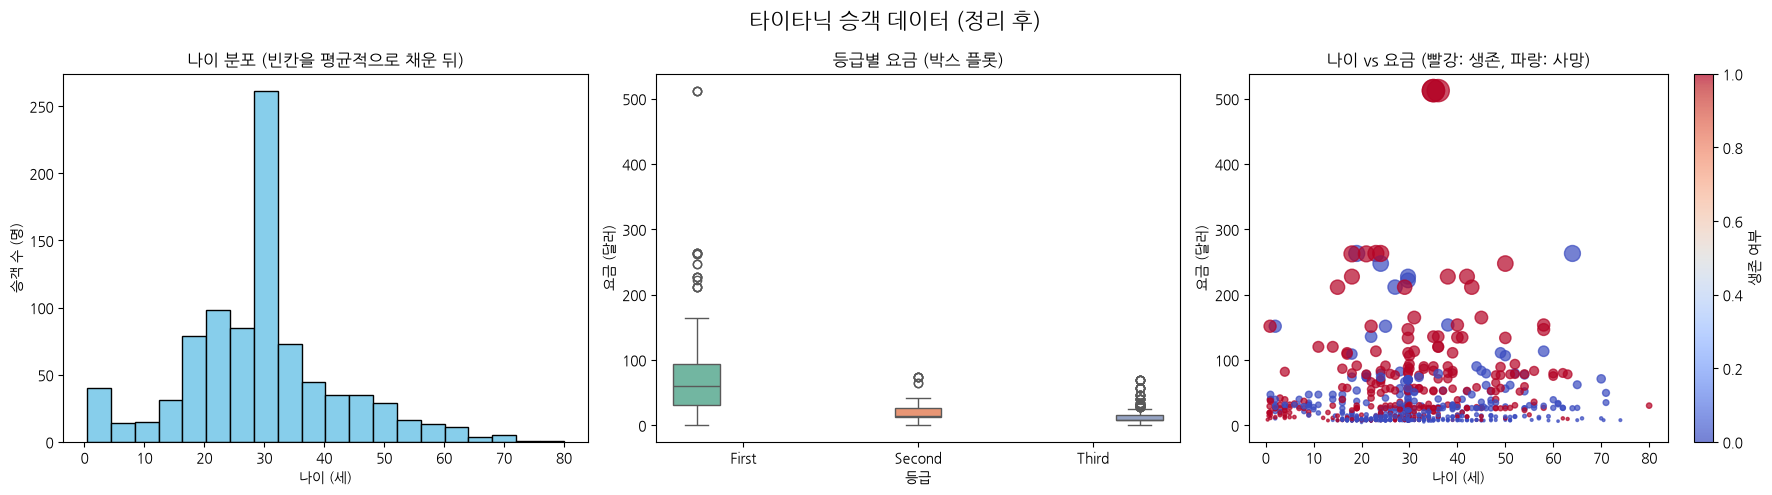

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("타이타닉 승객 데이터 (정리 후)", fontsize=16)

axes[0].hist(df["age"], bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("나이 분포 (빈칸을 평균적으로 채운 뒤)")
axes[0].set_xlabel("나이 (세)")
axes[0].set_ylabel("승객 수 (명)")

sns.boxplot(x="class", y="fare", data=df, ax=axes[1], hue="class", palette="Set2", legend=False)
axes[1].set_title("등급별 요금 (박스 플롯)")
axes[1].set_xlabel("등급")
axes[1].set_ylabel("요금 (달러)")

sc = axes[2].scatter(df["age"], df["fare"], c=df["survived"], cmap="coolwarm", s=df["fare"] / 2, alpha=0.7)
axes[2].set_title("나이 vs 요금 (빨강: 생존, 파랑: 사망)")
axes[2].set_xlabel("나이 (세)")
axes[2].set_ylabel("요금 (달러)")
fig.colorbar(sc, ax=axes[2], label="생존 여부")

plt.tight_layout()
plt.show()

In [12]:
ages = df["age"]
print("pandas var :", round(ages.var(), 3))
print("numpy var :", round(np.var(ages), 3))
print("numpy ddof=1:", round(np.var(ages, ddof=1), 3))

num = df.select_dtypes("number")
print(num.columns.tolist())
num.corr().round(2)

df.select_dtypes("number").corr()["survived"].round(2)
df.groupby(df["deck"] == "Unknown")["survived"].mean().round(3)

pandas var : 169.052
numpy var : 168.863
numpy ddof=1: 169.052
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


deck
False    0.670
True     0.299
Name: survived, dtype: float64